# 2 · Climb the ladder

Notebook 1 gave us a budget (5.2 TFLOP to train, 24 MFLOP per test image) and a list
of knobs whose cost we know in advance. This notebook finds out what each knob is worth
in accuracy, one question at a time, and climbs from where the leaderboard is to a
model inside the budget.

Every experiment here follows the same five steps, and so should yours:

1. **A question**, about one thing: "at the same compute, is a wider network or a
   longer training better?"
2. **A prediction**, written down before running anything. It keeps us honest: a result
   that surprises us is the one to look at twice.
3. **A fair test**: the settings differ in that one thing only, and each runs 3 times
   with different random seeds.
4. **A decision rule, fixed in advance**: a difference counts only if it is more than
   twice its standard error (see below). Otherwise we keep the simpler or cheaper option.
5. **A line in `NOTES.md`**: question, prediction, result, decision.

## How the runs were made

We ran about 200 trainings: far too many for a laptop (each takes 1 to 5 minutes on a
CPU). They ran on one rented GPU, 8 at a time, for about an hour, which cost about
a dollar. The GPU only makes them faster: the code, the settings and the compute counts
are exactly what a CPU would do. Every finished run is one line in `runs/<experiment>.jsonl`,
and this notebook only reads those files, so it runs in seconds anywhere.

To rerun one experiment yourself: the settings of each are in `plans.py`, and

```sh
python lab.py 2-recipe --device cuda --workers 6   # on a GPU
python lab.py 2-recipe                             # on a CPU: hours
```

Or try one setting on a quarter of the images, right here (about a minute on a laptop):

In [1]:
import lab
import matplotlib.pyplot as plt
import pandas as pd
from model import Config

pd.set_option("display.width", 120)
QUICK_TRY = False  # True: train one small model here, to see that the numbers are real
if QUICK_TRY:
    print(lab.run(Config(widths=(12, 24, 48), epochs=4, tta=1), quick=True))

## How big is a difference by chance?

Train the same settings twice with different seeds and you get two different
accuracies: the starting weights, the order of the images and the random turns all
change. Before comparing settings, we need to know how large that wobble is.

- The **standard deviation (sd)** of the 3 runs says how much one run wobbles.
- The **standard error (se)** of their mean is sd / √3: how far the mean of 3 runs may
  be from the mean of infinitely many. The tables below show it.
- Two settings, each a mean of 3 runs, differ by luck alone with a standard error of
  √(se₁² + se₂²). **A difference bigger than 2 of those happens by luck only about 1
  time in 20**: we call that real. `lab.compare` does this sum.

All accuracies are on the same 4,320 held-back training images (the split with
`seed=1`). We only look at other splits at the very end (notebook 3): a setting chosen
because it did well on these images is a little lucky on exactly these images.

## Experiment 0 · Can we reproduce the leader?

**Question.** Does our harness, with the leader's settings, give the leader's accuracy?
If it did not, every comparison after this one would be suspect.

**Prediction.** About 96.5%, like the leaderboard (on other images, so not exactly).

We also answer a second question for free. The leader looks at each test image in 8
orientations and averages the answers. The same trained weights can answer with 1, 2,
4 or 8 orientations, so each run tells us what every extra orientation buys, with no
luck of training in the comparison.

In [2]:
leader = lab.load("0-leader")
display(lab.summary(leader))
views = pd.DataFrame(list(leader["accuracy_by_views"])).astype(float) * 100
print("accuracy by number of orientations (mean of 3 runs):")
print(views.mean().round(2).to_string())

,accuracy,se,sd,runs,train_tflop,predict_mflop,parameters
label,,,,,,,
leader,96.86,0.16,0.27,3,26.22,119.2,174274.0


accuracy by number of orientations (mean of 3 runs):
1    96.16
2    96.61
4    96.84
8    96.86


**Result.** 96.9% (± 0.2): the leader is reproduced. (The leaderboard's 96.6% is on
the 5,400 test images; ours is on 4,320 different ones. A gap of 0.3 is within what two
different sets of images give.)

The orientations: answering in 2 of them instead of 1 buys about 0.45 points, 4 buys
another 0.2, and the last 4 buy nothing we can measure. **Four orientations give all
of the benefit at half the cost of eight.** We note it and come back to it at the end.

## Experiment 1 · A bigger network, or a longer training?

**Question.** For the same compute, which is better: a wider network trained for fewer
epochs, or a narrower one trained for more? We scale the leader's widths
(24, 48, 96) by 0.5, 0.75, 1 and 1.5, and train each for 4, 8 and 16 epochs.

**Prediction.** Somewhere in between: a tiny network cannot learn enough, and a huge
one does not get enough epochs. We expected the leader's width to be about right.

In [3]:
grid = lab.load("1-size-and-time")
table = lab.summary(grid)
display(table)

,accuracy,se,sd,runs,train_tflop,predict_mflop,parameters
label,,,,,,,
width 0.5 x 4 epochs,85.26,0.23,0.41,3,0.99,32.4,44230.0
width 0.5 x 8 epochs,89.36,0.24,0.42,3,1.99,32.4,44230.0
width 0.75 x 4 epochs,86.13,0.13,0.22,3,2.15,69.0,98524.0
width 0.5 x 16 epochs,93.36,0.42,0.73,3,3.98,32.4,44230.0
width 1.0 x 4 epochs,86.33,0.19,0.33,3,3.75,119.2,174274.0
width 0.75 x 8 epochs,90.09,0.33,0.57,3,4.30,69.0,98524.0
width 0.75 x 16 epochs,94.14,0.10,0.17,3,8.60,69.0,98524.0
width 1.0 x 8 epochs,90.69,0.68,1.18,3,7.49,119.2,174274.0
width 1.5 x 4 epochs,86.53,0.38,0.66,3,8.26,260.1,390142.0


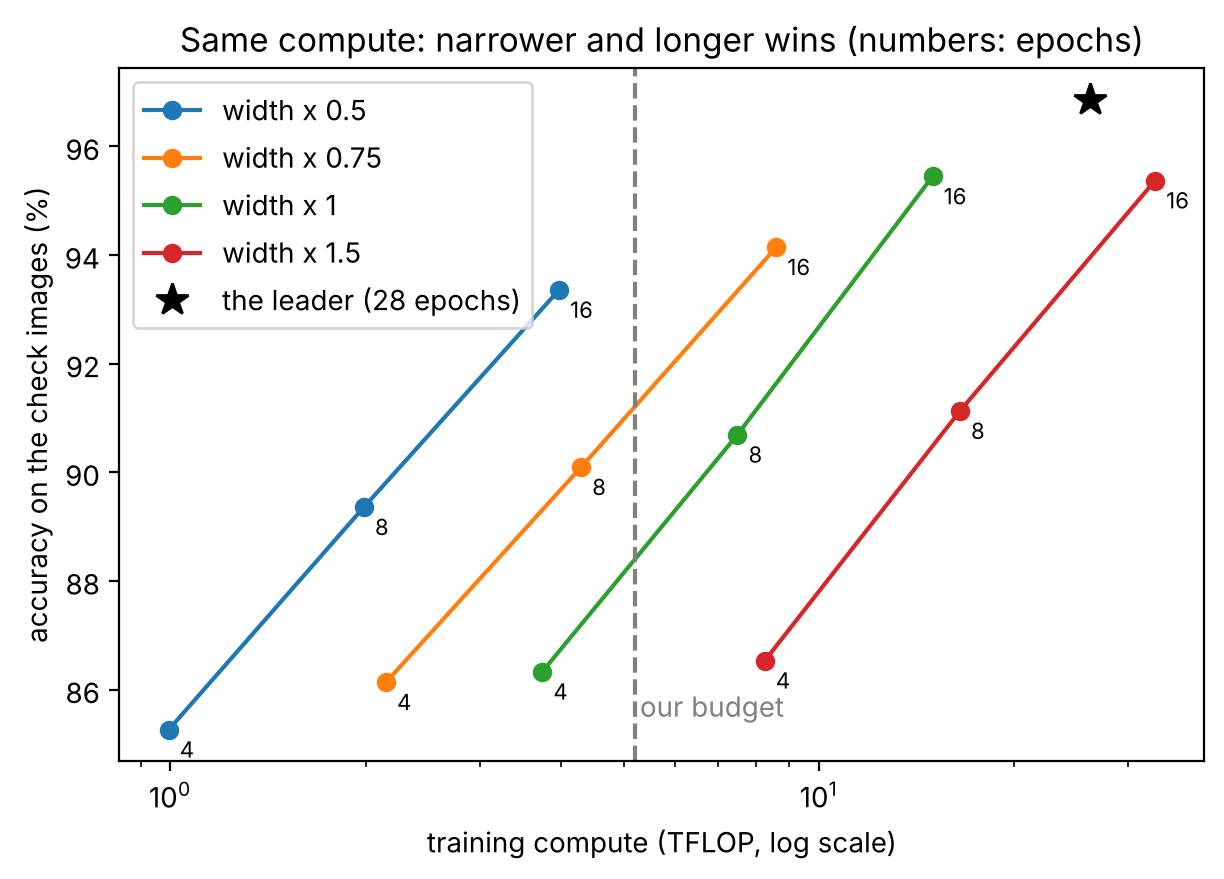

In [4]:
grid["width"] = [w[0] / 24 for w in lab.setting(grid, "widths")]
grid["epochs"] = lab.setting(grid, "epochs")
means = grid.groupby(["width", "epochs"]).agg(
    accuracy=("accuracy", "mean"), flop=("train_flops_full", "mean")
)

fig, ax = plt.subplots(figsize=(7, 4.5))
for width, rows in means.groupby(level="width"):
    rows = rows.droplevel("width")
    ax.plot(rows["flop"] / 1e12, 100 * rows["accuracy"], "o-", label=f"width x {width:g}")
    for epochs, row in rows.iterrows():
        ax.annotate(
            f"{epochs}",
            (row["flop"] / 1e12, 100 * row["accuracy"]),
            textcoords="offset points",
            xytext=(4, -10),
            fontsize=8,
        )
lead = lab.summary(leader).iloc[0]
ax.plot(lead["train_tflop"], lead["accuracy"], "k*", markersize=12, label="the leader (28 epochs)")
ax.axvline(5.2, color="gray", linestyle="--")
ax.text(5.3, 85.5, "our budget", color="gray")
ax.set_xscale("log")
ax.set_xlabel("training compute (TFLOP, log scale)")
ax.set_ylabel("accuracy on the check images (%)")
ax.set_title("Same compute: narrower and longer wins (numbers: epochs)")
ax.legend()
plt.show()

**Result.** The prediction was wrong, and that is the most useful thing in this
notebook. Read the chart at one amount of compute, for example 4 TFLOP:

| at about 4 TFLOP | accuracy |
|---|---|
| width x 1, 4 epochs | 86.3% |
| width x 0.75, 8 epochs | 90.1% |
| width x 0.5, 16 epochs | 93.4% |

**Epochs matter far more than width.** Each doubling of the epochs adds about 4 points,
whatever the width; each doubling of the width adds less than 1, and costs 4 times as
much. And the curves have not flattened yet at 16 epochs: these networks are still
learning when training stops.

**Decision.** Spend the budget on epochs, not on width. The next question writes
itself: how far does this go? Even narrower networks, for even longer (experiment 4).
But first, two questions that are cheap to answer at one fixed point, 16 epochs at width
0.5 (about 4 TFLOP), which we call *the probe*: how should we train (experiment 2), and
what shape should the network have (experiment 3)?

## Experiment 2 · How should we train?

**Question.** At the probe (width 0.5, 16 epochs), which of the usual training tricks
are worth anything? Each setting changes one thing. All but the last cost exactly the
same FLOPs: they change *how* the network learns, not how much arithmetic it does.

**Prediction.** Small gains each (a few tenths of a point), mostly too small to tell
apart from luck with 3 runs. We had no strong guess for any single one.

In [5]:
recipe = lab.load("2-recipe")
display(lab.summary(recipe).drop(columns="sd"))
for label in lab.summary(recipe).index[1:]:
    print(lab.compare(recipe, "probe", label))

,accuracy,se,runs,train_tflop,predict_mflop,parameters
label,,,,,,
lr 0.012,93.56,0.53,3,3.98,32.4,44230.0
probe,93.37,0.26,3,3.98,32.4,44230.0
lr 0.003,92.62,0.27,3,3.98,32.4,44230.0
batch 256,92.63,0.41,3,3.98,32.4,44230.0
lr 0.024,93.79,0.28,3,3.98,32.4,44230.0
batch 64,94.41,0.13,3,3.98,32.4,44230.0
no weight decay,93.16,0.35,3,3.98,32.4,44230.0
weight decay 0.05,93.58,0.26,3,3.98,32.4,44230.0
average weights 0.99,93.57,0.12,3,3.98,32.4,44230.0


probe vs probe: +0.00 points ± 0.37 -> could be luck
lr 0.003 vs probe: -0.75 points ± 0.37 -> real
batch 256 vs probe: -0.74 points ± 0.49 -> could be luck
lr 0.024 vs probe: +0.42 points ± 0.38 -> could be luck
batch 64 vs probe: +1.04 points ± 0.29 -> real
no weight decay vs probe: -0.21 points ± 0.44 -> could be luck
weight decay 0.05 vs probe: +0.21 points ± 0.37 -> could be luck
average weights 0.99 vs probe: +0.20 points ± 0.29 -> could be luck
label smoothing 0.1 vs probe: +0.20 points ± 0.36 -> could be luck
average weights 0.998 vs probe: +0.12 points ± 0.35 -> could be luck
blocks start as identity vs probe: -0.56 points ± 0.51 -> could be luck
no turning or mirroring vs probe: -0.28 points ± 0.45 -> could be luck
half the epochs at 32x32 vs probe: -0.97 points ± 0.44 -> real


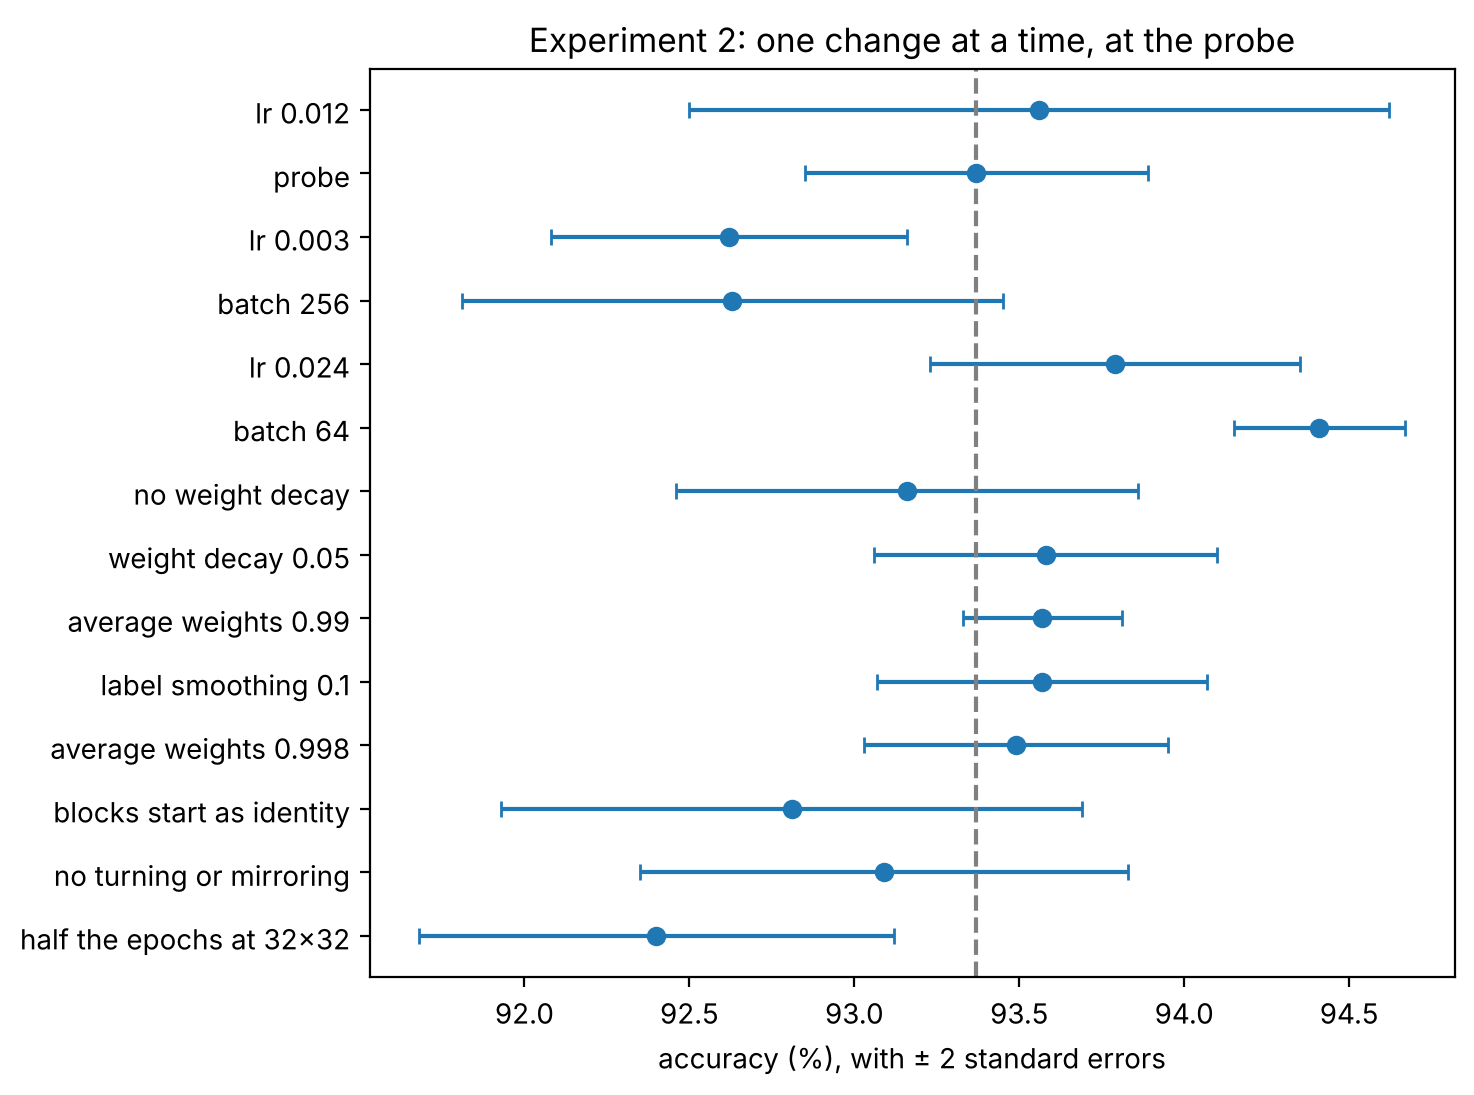

In [6]:
def bars(table, title, reference="probe"):
    """Each setting's mean accuracy, with 2 standard errors either side."""
    s = lab.summary(table)
    fig, ax = plt.subplots(figsize=(7, 0.35 * len(s) + 1))
    ax.errorbar(s["accuracy"], s.index, xerr=2 * s["se"], fmt="o", capsize=3)
    ax.axvline(s.loc[reference, "accuracy"], color="gray", linestyle="--")
    ax.invert_yaxis()
    ax.set_xlabel("accuracy (%), with ± 2 standard errors")
    ax.set_title(title)
    plt.show()


bars(recipe, "Experiment 2: one change at a time, at the probe")

**Result.** Most changes are within luck of the probe: weight decay, a running average
of the weights, label smoothing, starting the blocks as "do nothing", and even turning
and mirroring (which needs more epochs to pay off: the demo found the same). We keep
none of them: a change that cannot show its worth is complexity we do not need.

Three results stand out:

- **Batch size 64 instead of 128: +1.0 point (real).** Same images, same FLOPs, but
  twice as many learning steps, each from half as many images. Batch 256 points the same
  way (−0.7). That fits experiment 1: these networks are short of *learning steps*, not
  of size.
- **A smaller learning rate (0.003) is worse; larger ones (0.012, 0.024) are a little
  better** but within luck. With a smaller batch the best rate may move: experiment 5
  tests the two together.
- **Half the epochs on 32x32 images: −1.0 point, but 37% less compute.** This
  comparison is not fair: it saves compute and spends none of it. Experiment 6 gives the
  saving back as more epochs.

## Experiment 3 · What shape should the network have?

**Question.** At the probe, does the compute sit in the right places? We try a
cheaper first layer that cuts the image into 4x4 squares (no overlap, no max pool),
dropping stage 1 (the most expensive), moving width to the later stages, and more depth.

**Prediction.** The 4x4 squares lose little (they see every pixel once); dropping
stage 1 loses some; more depth wins a little but costs a lot.

,accuracy,se,runs,train_tflop,predict_mflop,parameters
label,,,,,,
probe,93.49,0.34,3,3.98,32.4,44230.0
first layer: 4x4 squares,91.01,0.16,3,3.72,29.5,44482.0
no stage 1,92.43,0.39,3,2.60,21.8,41590.0
"no stage 1, wider (16, 32, 64)",93.51,0.35,3,4.42,36.4,73370.0
"wider late (12, 32, 64)",93.69,0.53,3,5.47,44.0,74614.0
"deeper (1, 2, 2)",94.17,0.22,3,6.73,53.7,96358.0


first layer: 4x4 squares vs probe: -2.48 points ± 0.38 -> real
no stage 1 vs probe: -1.06 points ± 0.52 -> real
no stage 1, wider (16, 32, 64) vs probe: +0.02 points ± 0.49 -> could be luck
wider late (12, 32, 64) vs probe: +0.20 points ± 0.63 -> could be luck
deeper (1, 2, 2) vs probe: +0.68 points ± 0.40 -> could be luck


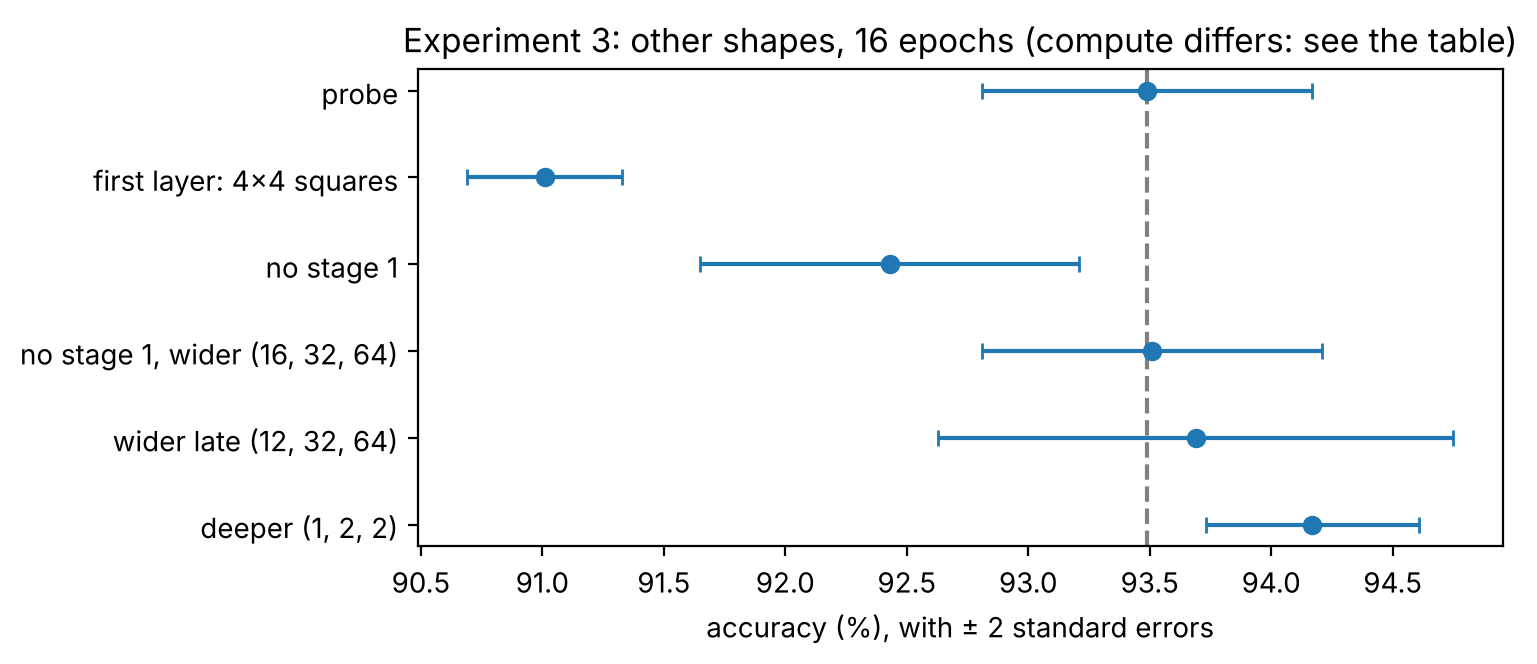

In [7]:
shapes = lab.load("3-shape")
display(lab.summary(shapes).drop(columns="sd"))
for label in lab.summary(shapes).index[1:]:
    print(lab.compare(shapes, "probe", label))
bars(shapes, "Experiment 3: other shapes, 16 epochs (compute differs: see the table)")

**Result.**

- **4x4 squares: −2.5 points (real).** The prediction was wrong. The leader's first
  layer looks at overlapping 3x3 windows and then keeps the strongest answer in each
  2x2 square (max pool); fine texture survives that, and texture is what tells a pasture
  from a crop field. Cutting the image into squares with one linear step loses it.
- **No stage 1: −1.1 points, for 35% less compute.** At equal compute that is about a
  tie with simply training for fewer epochs (from experiment 1). Not worth it.
- **Wider late stages, or deeper: +0.2 and +0.7, within luck, for 37% and 70% more
  compute.** Experiment 1 says the same compute spent on epochs buys about 3 points.

**Decision.** Keep the leader's shape: it puts its compute in sensible places. Like
experiment 1, this says the lever is the number of learning steps, not the network.

## Experiment 4 · How far does "narrower and longer" go?

**Question.** Experiment 1 said: for the same compute, more epochs beat more width.
Does that keep going if we make the network even narrower (a quarter or a third of the
leader's width) and train it even longer (up to 128 epochs)?

**Prediction.** It cannot go on forever: a network that is too small cannot hold what
it needs to know, however long it trains. We guessed the best width would be about a
third of the leader's.

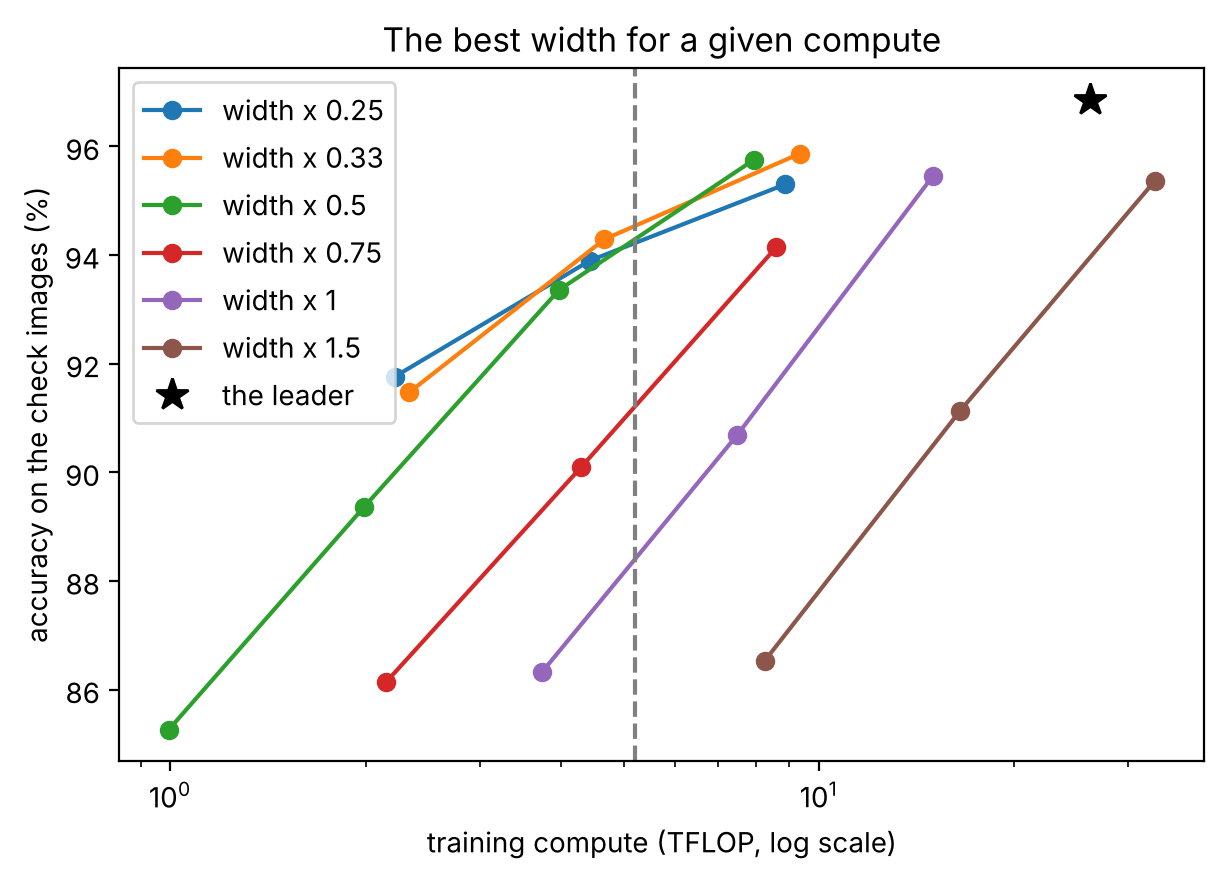

,accuracy,se,runs,train_tflop,predict_mflop,parameters
label,,,,,,
width 0.25 x 32 epochs,91.76,0.40,3,2.22,9.4,11392.0
width 0.33 x 20 epochs,91.47,0.52,3,2.34,15.6,19954.0
width 0.25 x 64 epochs,93.90,0.17,3,4.44,9.4,11392.0
width 0.33 x 40 epochs,94.29,0.24,3,4.67,15.6,19954.0
width 0.25 x 128 epochs,95.30,0.29,3,8.87,9.4,11392.0
width 0.5 x 32 epochs,95.76,0.05,3,7.95,32.4,44230.0
width 0.33 x 80 epochs,95.87,0.24,3,9.35,15.6,19954.0


In [8]:
sizes = pd.concat([lab.load("1-size-and-time"), lab.load("4-smaller-longer")])
sizes["width"] = [w[0] / 24 for w in lab.setting(sizes, "widths")]
sizes["epochs"] = lab.setting(sizes, "epochs")
means = sizes.groupby(["width", "epochs"]).agg(
    accuracy=("accuracy", "mean"), flop=("train_flops_full", "mean")
)

fig, ax = plt.subplots(figsize=(7, 4.5))
for width, rows in means.groupby(level="width"):
    rows = rows.droplevel("width")
    ax.plot(rows["flop"] / 1e12, 100 * rows["accuracy"], "o-", label=f"width x {width:.2g}")
ax.plot(lead["train_tflop"], lead["accuracy"], "k*", markersize=12, label="the leader")
ax.axvline(5.2, color="gray", linestyle="--")
ax.set_xscale("log")
ax.set_xlabel("training compute (TFLOP, log scale)")
ax.set_ylabel("accuracy on the check images (%)")
ax.set_title("The best width for a given compute")
ax.legend()
plt.show()
display(lab.summary(lab.load("4-smaller-longer")).drop(columns="sd"))

**Result.** The prediction held. At about 4.5 TFLOP:

| | accuracy |
|---|---|
| width x 0.25, 64 epochs | 93.9% |
| **width x 0.33, 40 epochs** | **94.3%** |
| width x 0.5, 16 epochs | 93.4% |

and at about 9 TFLOP the same order: 0.25 is worst (95.3%), 0.33 and 0.5 are tied
(95.9% and 95.8%). The curves for 0.33 and 0.5 lie almost on top of each other: in
that range, how the compute is split between width and epochs hardly matters. Below a
third of the leader's width, the network is too small.

**Decision.** A third to a half of the leader's width. Within our budget that means
20 to 45 epochs, depending on what else we change.

One more thing hides in the data: these small networks gain much more from looking at
the test image in 4 orientations than the leader did (about +1.2 points instead of
+0.7). A small network has learned less about what turned images look like, and the
averaging makes up for some of that. At width 0.33 four views cost 8 MFLOP, well inside
our budget of 24.

## Experiment 5 · Batch size and learning rate, together

**Question.** Batch 64 beat batch 128 (experiment 2). Do even smaller batches help, and
does each batch size want its own learning rate? Two settings that may depend on each
other must be tested together, as a grid: changing one at a time could miss the best
pair.

**Prediction.** A smaller batch makes noisier steps, so it should want a smaller
learning rate.

lr,0.003,0.006,0.012,0.024
batch,,,,
32,94.35,94.60,94.67,94.77
64,93.63,94.39,94.57,94.77
128,92.69,93.39,93.58,93.67


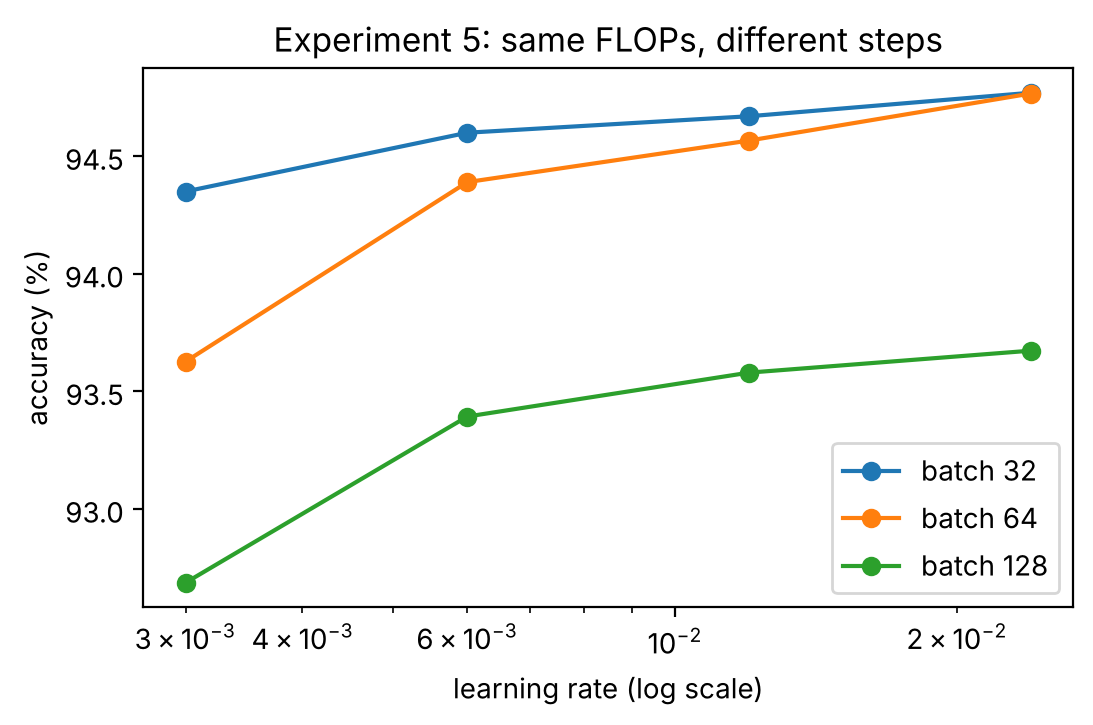

In [9]:
grid5 = lab.load("5-batch-and-lr")
grid5["batch"] = lab.setting(grid5, "batch_size")
grid5["lr"] = lab.setting(grid5, "lr")
mean5 = grid5.pivot_table(index="batch", columns="lr", values="accuracy") * 100
display(mean5.round(2))

fig, ax = plt.subplots(figsize=(6, 3.5))
for batch, row in mean5.iterrows():
    ax.plot(row.index, row.values, "o-", label=f"batch {batch}")
ax.set_xscale("log")
ax.set_xlabel("learning rate (log scale)")
ax.set_ylabel("accuracy (%)")
ax.set_title("Experiment 5: same FLOPs, different steps")
ax.legend()
plt.show()

**Result.** The prediction was wrong again. **A higher learning rate is better for
every batch size**, up to the largest we tried (0.024, four times the leader's). And
batch 32 is no better than batch 64 once the rate is high: both reach 94.8%, against
93.4% for the probe. Batch 128 stays a point behind whatever the rate.

**Decision.** Batch 64 and learning rate 0.024: +1.4 points for no compute at all.
Batch 32 would tie, but on a CPU it trains half as fast (7.2 instead of 3.8 seconds per
epoch on 4 cores), and GitHub's clock is limited. The best rate may lie above 0.024,
outside the grid: experiment 7 tries one step further.

## Experiment 6 · Small images first, at equal compute

**Question.** Training on 32x32 images (each 2x2 square of pixels averaged into one)
costs 4 times less per epoch. Experiment 2 lost a point doing it for half the epochs,
but it also did 37% less work. Here every setting costs about 4 TFLOP: the epochs saved
by small images are given back as more epochs.

**Prediction.** A tie: more epochs, but less detail in most of them.

In [10]:
low = lab.load("6-low-res-fair")
display(lab.summary(low).drop(columns="sd"))
first = lab.summary(low).index[0]
for label in lab.summary(low).index[1:]:
    print(lab.compare(low, first, label))

,accuracy,se,runs,train_tflop,predict_mflop,parameters
label,,,,,,
probe: 16 epochs at 64x64,93.50,0.23,3,3.98,32.4,44230.0
"26 epochs, half at 32x32",94.25,0.10,3,4.04,32.4,44230.0
"36 epochs, 3/4 at 32x32",94.38,0.18,3,3.92,32.4,44230.0


26 epochs, half at 32x32 vs probe: 16 epochs at 64x64: +0.75 points ± 0.25 -> real
36 epochs, 3/4 at 32x32 vs probe: 16 epochs at 64x64: +0.88 points ± 0.29 -> real


**Result.** Both beat the probe at the same compute: +0.75 points with half the epochs
at 32x32, +0.9 with three quarters (both real). The fine detail is only needed in the
last part of training: in the early epochs the network learns colors and coarse
shapes, which survive at half the size. The last epochs at full size let it learn the
fine texture, and set its batch normalization to full-size images, which are the only
ones it will see in the test.

**Decision.** Train most of the epochs on 32x32 images, and spend the saving on more
epochs. How much is "most" is the next question, together with everything else.

## Experiment 7 · Put it together, at the budget

**Question.** With the batch size and learning rate of experiment 5, at a width of
1/3 or 1/2 (experiment 4), and with 1/2, 3/4 or 7/8 of the epochs on small images
(experiment 6), what is the best accuracy that fits in 5 TFLOP? Each setting trains for
exactly as many epochs as fit in the budget (`lab.train_flops` counts them), so they are
all compared at the same compute.

**Prediction.** Adding up the gains of experiments 4 to 6 to the probe's 93.4%: about
96.5%.

In [11]:
combined = lab.load("7-combined")
display(lab.summary(combined).sort_values("accuracy", ascending=False).drop(columns="sd"))
print("each seed separately:")
display((combined.pivot_table(index="label", columns="seed", values="accuracy") * 100).round(2))

,accuracy,se,runs,train_tflop,predict_mflop,parameters
label,,,,,,
"width 0.5, 45 epochs, 0.75 at 32x32, lr 0.048",96.04,0.21,3,4.85,32.4,44230.0
"width 0.33, 98 epochs, 0.75 at 32x32, lr 0.048",95.94,0.23,3,4.97,15.6,19954.0
"width 0.5, 45 epochs, 0.75 at 32x32",95.91,0.17,3,4.85,32.4,44230.0
"width 0.5, 32 epochs, 0.5 at 32x32",95.91,0.17,3,4.97,32.4,44230.0
"width 0.33, 68 epochs, 0.5 at 32x32",95.83,0.27,3,4.97,15.6,19954.0
"width 0.33, 98 epochs, 0.75 at 32x32",95.73,0.43,3,4.97,15.6,19954.0
"width 0.5, 59 epochs, 0.875 at 32x32",95.30,0.08,3,4.97,32.4,44230.0
"width 0.33, 123 epochs, 0.875 at 32x32",95.14,0.13,3,4.91,15.6,19954.0


each seed separately:


seed,0,1,2
label,,,
"width 0.33, 123 epochs, 0.875 at 32x32",95.39,94.98,95.05
"width 0.33, 68 epochs, 0.5 at 32x32",96.34,95.72,95.44
"width 0.33, 98 epochs, 0.75 at 32x32",96.55,95.56,95.09
"width 0.33, 98 epochs, 0.75 at 32x32, lr 0.048",96.39,95.76,95.67
"width 0.5, 32 epochs, 0.5 at 32x32",95.86,96.23,95.65
"width 0.5, 45 epochs, 0.75 at 32x32",96.23,95.67,95.83
"width 0.5, 45 epochs, 0.75 at 32x32, lr 0.048",95.63,96.20,96.30
"width 0.5, 59 epochs, 0.875 at 32x32",95.30,95.16,95.44


**Result.** About 96.0%, half a point short of the prediction: gains found one at a
time rarely add up completely, because several of them fix the same weakness (here, too
few learning steps). Among the settings:

- 1/2 or 3/4 of the epochs on small images, width 1/3 or 1/2, learning rate 0.024 or
  0.048: **all within luck of each other**, 95.7 to 96.0%. A wide plateau, which is good
  news: the result does not hang on one lucky setting.
- 7/8 of the epochs on small images is too many (−0.6): the network needs time at full
  size to learn fine texture.

Notice also how much the **seeds** now differ: the same setting scores 95.1% with one
seed and 96.6% with another. With 3 runs, the standard error of a mean is 0.2 to 0.4
points, so we cannot rank settings that differ by less. When the differences you are
looking for shrink, you need more runs per setting (experiment 8 uses 6).

**Decision.** A *candidate*: width 1/2, 45 epochs, 3/4 of them on 32x32 images, batch
64, learning rate 0.024 (4.9 TFLOP). The leader scores 96.9% on these images, so we are
about 0.9 points short, with a fifth of its compute.

## Experiment 8 · Does the network memorize?

**Question.** A long training can make a network memorize its training images instead
of learning what generalizes. The usual remedies cost no FLOPs: label smoothing, a
running average of the weights, more weight decay, and *mixup* (training on blends of
two images, with the same blend of their labels). They were neutral at 16 epochs
(experiment 2); at 45 epochs they may not be. The differences we are looking for are a
few tenths of a point, so each setting runs with 6 seeds.

**Prediction.** Small gains, +0.2 to +0.5 each.

In [12]:
reg = lab.load("8-regularize")
table8 = lab.summary(reg).drop(columns="sd")
table8["training accuracy"] = (
    reg.groupby("label", sort=False)["train_accuracy"].mean() * 100
).round(2)
display(table8)
for label in table8.index[1:]:
    print(lab.compare(reg, "candidate", label))

,accuracy,se,runs,train_tflop,predict_mflop,parameters,training accuracy
label,,,,,,,
candidate,95.71,0.07,6,4.85,32.4,44230.0,95.04
label smoothing 0.1,95.90,0.10,6,4.85,32.4,44230.0,94.96
average weights 0.999,95.57,0.15,6,4.85,32.4,44230.0,95.12
weight decay 0.05,95.64,0.06,6,4.85,32.4,44230.0,94.99
mixup 0.2,95.18,0.09,6,4.85,32.4,44230.0,50.71


label smoothing 0.1 vs candidate: +0.19 points ± 0.12 -> could be luck
average weights 0.999 vs candidate: -0.14 points ± 0.17 -> could be luck
weight decay 0.05 vs candidate: -0.07 points ± 0.09 -> could be luck
mixup 0.2 vs candidate: -0.53 points ± 0.11 -> real


**Result.** None helps; mixup hurts (−0.5, real). The last column says why. On its
training images (in the last epoch, turned and mirrored), the candidate is right 95.0%
of the time: **less than on the check images it never saw** (95.7%). A network that
memorizes does much better on its training images than on new ones. This one does not
memorize at all: it **underfits**. Every remedy above fights memorizing, a problem we
do not have; mixup even makes the training task harder. (Its training accuracy is low
by construction: the labels are blends.)

**Lesson.** Before you reach for a remedy, check the diagnosis: compare training
accuracy with check accuracy. It costs nothing, and it would have predicted this whole
experiment.

**Decision.** No regularizers. An underfitting network needs more learning, which
means more compute or more efficient learning. Experiment 9 tries a different
optimizer; experiment 10 measures what more compute would buy.